# NBA points prediction: a visible first experiment

Run cells from top to bottom. Each row is one player appearance; the target is points scored.
We compare the same 18 pregame features across several models, keeping names for inspection.

**Colab:** open this notebook with File → Upload notebook, use a CPU runtime, and upload the
**two cleaned CSVs** when the upload cell runs. No project modules or NBA API calls are needed.
Colab normally provides pandas, NumPy, matplotlib, and scikit-learn. If an import fails,
install these four packages in a separate cell with `%pip install pandas numpy matplotlib scikit-learn`.
Save/download results before a Colab runtime ends; its temporary files are not persistent.

**Local Jupyter:** open from the project root or its `notebooks` directory.

The saved outputs demonstrate an **exploratory 2020–21 → 2021–22** run, not our final study.
Set `EXPERIMENT = "study"` below when the five-season training export and 2025–26 validation export are ready.
Never use 2026–27 to select models or features. No random split of player-game rows.


In [ ]:
from pathlib import Path
import pickle
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_pinball_loss

print("scikit-learn version:", sklearn.__version__)


: 

## 1. Choose and load the data

Start with `exploratory` using the two complete seasonal CSVs already prepared.
For `study`, use `train_2020_2025.csv` and `validation_2025_2026.csv`.
The selection is explicit: missing files never trigger a silent fallback to different seasons.


In [ ]:
EXPERIMENT = "exploratory"  # Change to "study" when those CSVs are ready.

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

ROOT = Path.cwd()
if not IN_COLAB and ROOT.name == "notebooks":
    ROOT = ROOT.parent

if EXPERIMENT == "exploratory":
    train_name = "features_2020-21.csv"
    validation_name = "features_2021-22.csv"
    DATA_DIR = ROOT / "data/clean/seasons"
elif EXPERIMENT == "study":
    train_name = "train_2020_2025.csv"
    validation_name = "validation_2025_2026.csv"
    DATA_DIR = ROOT / "data/clean"
else:
    raise ValueError("Choose exploratory or study")

if IN_COLAB:
    DATA_DIR = ROOT
    if not all((DATA_DIR / name).exists() for name in [train_name, validation_name]):
        print("Upload these two files:", train_name, "and", validation_name)
        files.upload()

train = pd.read_csv(DATA_DIR / train_name, dtype={"game_id": "string"})
validation = pd.read_csv(DATA_DIR / validation_name, dtype={"game_id": "string"})
print(f"{EXPERIMENT}: {len(train):,} training rows; {len(validation):,} validation rows")
display(train.head())


,season,game_id,game_date,player_id,player_name,team_id,team_abbreviation,opponent_id,points_last_5,points_last_10,points_season_avg,minutes_last_5,minutes_last_10,fga_last_10,fg3a_last_10,fta_last_10,opponent_defensive_rating,team_pace,opponent_pace,is_home,team_rest_days,opponent_rest_days,team_back_to_back,opponent_back_to_back,age,games_played_before,target_points
0,2020-21,0022000142,2021-01-10,101150,Lou Williams,1610612746,LAC,1610612741,7.0,8.9,8.9,20.6,20.3,8.1,2.3,1.4,114.8,97.35,105.00,1,1.0,1.0,0.0,0.0,34.207410,10,21
1,2020-21,0022000142,2021-01-10,201586,Serge Ibaka,1610612746,LAC,1610612741,11.0,12.5,12.5,29.8,25.6,10.0,3.3,1.7,114.8,97.35,105.00,1,1.0,1.0,0.0,0.0,31.313442,10,10
2,2020-21,0022000142,2021-01-10,201587,Nicolas Batum,1610612746,LAC,1610612741,13.4,10.5,10.5,31.6,29.4,7.2,4.3,1.6,114.8,97.35,105.00,1,1.0,1.0,0.0,0.0,32.074581,10,8
3,2020-21,0022000142,2021-01-10,201976,Patrick Beverley,1610612746,LAC,1610612741,9.4,8.7,8.7,29.4,25.6,6.6,4.2,1.1,114.8,97.35,105.00,1,1.0,1.0,0.0,0.0,32.498956,10,7
4,2020-21,0022000142,2021-01-10,203897,Zach LaVine,1610612741,CHI,1610612746,28.6,26.0,26.0,36.6,34.5,19.2,8.1,5.7,112.1,105.00,97.35,0,1.0,1.0,0.0,0.0,25.840366,10,45


exploratory: 17,903 training rows; 20,634 validation rows


## 2. Select inputs and check the time boundary

The explicit feature list excludes player names, IDs, and the current game's points.
The CSV preparation already shifts all histories to exclude the game being predicted.
These checks verify file structure and separation; they do not independently prove every
feature was generated without leakage.

During validation, histories update after earlier games finish. This is a sequence of
pregame predictions with a fixed model, not a forecast of the whole season on opening day.


In [ ]:
FEATURES = [
    "points_last_5", "points_last_10", "points_season_avg",
    "minutes_last_5", "minutes_last_10",
    "fga_last_10", "fg3a_last_10", "fta_last_10",
    "opponent_defensive_rating", "team_pace", "opponent_pace",
    "is_home", "team_rest_days", "opponent_rest_days",
    "team_back_to_back", "opponent_back_to_back", "age", "games_played_before",
]
TARGET = "target_points"
META = ["season", "game_id", "game_date", "player_id", "player_name"]

for frame in [train, validation]:
    assert len(frame) > 0, "Empty dataset"
    assert not frame[META + FEATURES + [TARGET]].isna().any().any(), "Missing values"
    frame["game_date"] = pd.to_datetime(frame["game_date"], errors="raise").dt.normalize()
    assert frame["game_date"].notna().all(), "Missing game dates"
    assert not frame.duplicated(["game_id", "player_id"]).any(), "Duplicate appearances"
    assert np.isfinite(frame[FEATURES + [TARGET]].to_numpy(dtype=float)).all(), "Invalid numbers"
    assert (frame[TARGET] >= 0).all(), "Negative target points"

assert train.game_date.max() < validation.game_date.min(), "Training must precede validation"
assert train[["game_id", "player_id"]].merge(
    validation[["game_id", "player_id"]], on=["game_id", "player_id"]
).empty, "Overlapping appearances"
if EXPERIMENT == "study":
    assert set(train.season) == {"2020-21", "2021-22", "2022-23", "2023-24", "2024-25"}
    assert set(validation.season) == {"2025-26"}

X_train, y_train = train[FEATURES], train[TARGET]
X_validation, y_validation = validation[FEATURES], validation[TARGET]

display(pd.DataFrame({
    "split": ["training", "validation"],
    "first_game": [train.game_date.min(), validation.game_date.min()],
    "last_game": [train.game_date.max(), validation.game_date.max()],
    "players": [train.player_id.nunique(), validation.player_id.nunique()],
    "rows": [len(train), len(validation)],
}))


,split,first_game,last_game,players,rows
0,training,2021-01-10,2021-05-16,484,17903
1,validation,2021-11-07,2022-04-10,494,20634


## 3. Compare simple models

- **Season average / ten-game average:** the reference predictions to beat.
- **Ridge:** linear regression with an L2 penalty on coefficients. Scaling is learned only from training data.
- **Small decision tree:** an interpretable nonlinear comparison; depth and minimum leaf size restrict complexity.
- **Boosted trees:** many small trees working together. L2 regularization and leaf limits are already part of this model.

These are starting settings, not optimized settings. Keep the features and evaluation rows fixed
when comparing algorithms. Later, keep the algorithm/settings fixed to test additional features.


In [ ]:
models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "Small tree": DecisionTreeRegressor(max_depth=5, min_samples_leaf=50, random_state=42),
    "Boosted trees": HistGradientBoostingRegressor(
        max_iter=200, max_leaf_nodes=15, learning_rate=0.05,
        l2_regularization=1.0, early_stopping=False, random_state=42,
    ),
}

predictions = validation[META + [TARGET]].copy()
predictions["Season average"] = validation["points_season_avg"]
predictions["Ten-game average"] = validation["points_last_10"]

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = np.maximum(model.predict(X_validation), 0)

methods = ["Season average", "Ten-game average", *models]

def compare_predictions(names):
    return pd.DataFrame([
        {"method": name,
         "MAE": mean_absolute_error(y_validation, predictions[name]),
         "RMSE": np.sqrt(mean_squared_error(y_validation, predictions[name]))}
        for name in names
    ]).set_index("method").sort_values("MAE")

scores = compare_predictions(methods)
display(scores.round(3))


,MAE,RMSE
method,,
Ridge,4.688,6.094
Boosted trees,4.745,6.164
Ten-game average,4.780,6.235
Season average,4.783,6.250
Small tree,4.800,6.200


## 4. See the errors

Lower MAE and RMSE are better. MAE is the average absolute miss in points; RMSE penalizes
large misses more strongly. A small difference on one validation period is not proof of
reliable superiority. We can later assess stability across seasons and use game/date-block
resampling for uncertainty in the *difference in model errors*.

`SELECTED_MODEL` controls the diagnostic plot and saved model. It does not silently select
whichever model has the smallest displayed error.


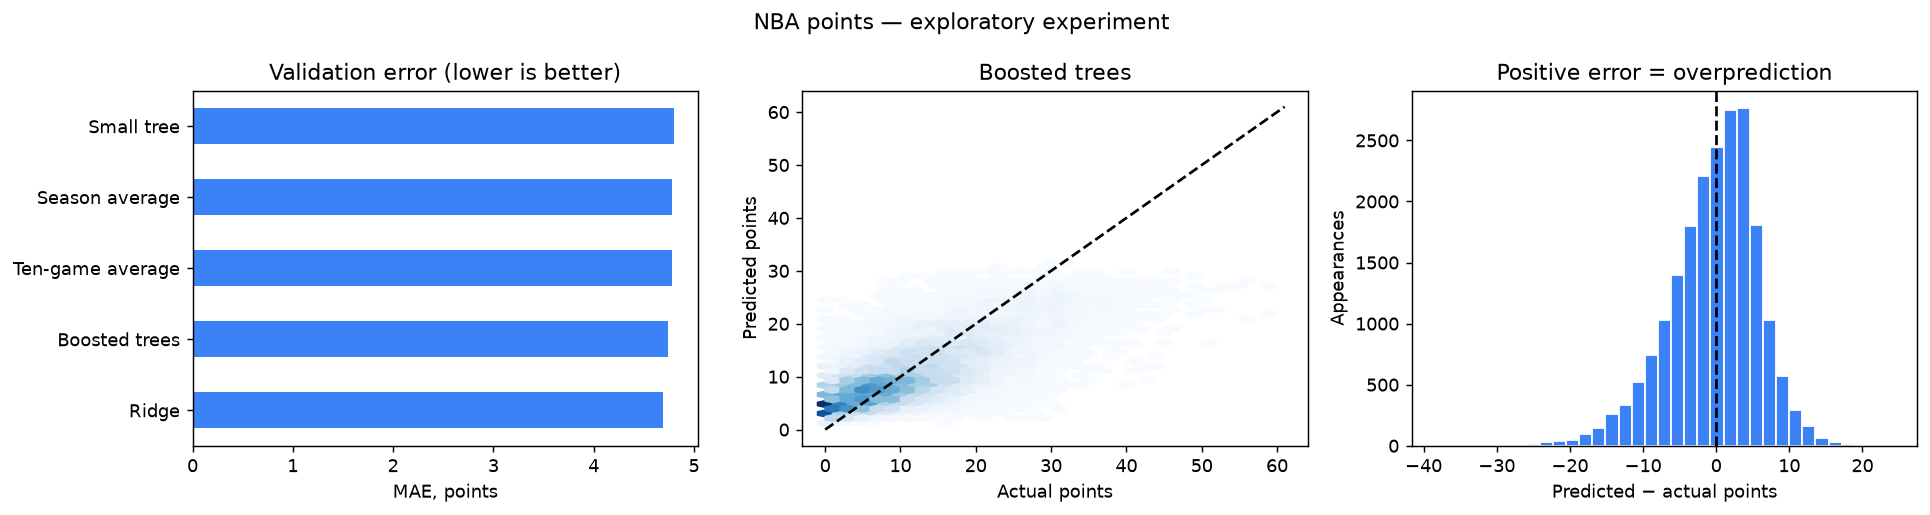

,season,game_id,game_date,player_id,player_name,target_points,Season average,Ten-game average,Ridge,Small tree,Boosted trees
0,2021-22,0022100139,2021-11-07,1627832,Fred VanVleet,21,18.7,18.7,18.659951,19.087719,18.168093
1,2021-22,0022100139,2021-11-07,1628384,OG Anunoby,16,20.6,20.6,20.971143,19.087719,15.742539
2,2021-22,0022100139,2021-11-07,1628449,Chris Boucher,6,5.1,5.1,5.614035,6.366852,4.437108
3,2021-22,0022100139,2021-11-07,1629004,Svi Mykhailiuk,5,8.2,8.2,8.311285,8.754974,7.486589
4,2021-22,0022100139,2021-11-07,1629018,Gary Trent Jr.,14,15.3,15.3,15.630463,16.079853,15.730622
5,2021-22,0022100139,2021-11-07,1630173,Precious Achiuwa,13,7.7,7.7,7.882336,8.058468,7.128119
6,2021-22,0022100139,2021-11-07,1630625,Dalano Banton,5,5.3,5.3,5.568278,6.366852,5.253982
7,2021-22,0022100140,2021-11-07,201937,Ricky Rubio,37,11.4,11.4,11.309781,12.613035,11.603173
8,2021-22,0022100140,2021-11-07,1628386,Jarrett Allen,18,14.6,14.6,13.368942,14.728916,14.079391
9,2021-22,0022100140,2021-11-07,1629012,Collin Sexton,8,16.8,16.8,16.301559,16.079853,15.929689


In [ ]:
SELECTED_MODEL = "Boosted trees"

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
scores["MAE"].plot.barh(ax=axes[0], color="#3b82f6")
axes[0].set(title="Validation error (lower is better)", xlabel="MAE, points", ylabel="")
axes[0].set_xlim(left=0)

axes[1].hexbin(y_validation, predictions[SELECTED_MODEL], gridsize=30, mincnt=1, cmap="Blues")
limit = max(y_validation.max(), predictions[SELECTED_MODEL].max()) + 1
axes[1].plot([0, limit], [0, limit], "--", color="black")
axes[1].set(title=SELECTED_MODEL, xlabel="Actual points", ylabel="Predicted points")

errors = predictions[SELECTED_MODEL] - y_validation
axes[2].hist(errors, bins=35, color="#3b82f6", edgecolor="white")
axes[2].axvline(0, color="black", linestyle="--")
axes[2].set(title="Positive error = overprediction", xlabel="Predicted − actual points", ylabel="Appearances")
fig.suptitle(f"NBA points — {EXPERIMENT} experiment")
plt.tight_layout()
plt.show()
display(predictions.head(10))


## 5. Optional: uncertainty in a player's next score

A point prediction does not describe the range of plausible outcomes. Fit the 10th and
90th conditional quantiles to target a **nominal 80% prediction interval**. This is not a
confidence interval for the average score, and coverage is not guaranteed.

Check **coverage** (fraction of actual scores inside) and **average width** together.
Wide intervals can achieve high coverage without being useful. Pinball loss evaluates the
raw quantile predictions; the interval score balances width with penalties for missed outcomes.
Compare these measures across future periods and player groups, not just globally.

Independent quantile models can cross. We report the crossing rate, then sort endpoints
and clamp them to zero. Coverage, width, and interval score refer to these final intervals.
No validation outcomes are used to adjust endpoints. Formal calibration would need a separate,
chronologically earlier calibration block and an untouched evaluation block; temporal changes
also complicate exchangeability-based coverage guarantees.


,interval evaluation
nominal_coverage,0.800
observed_coverage,0.742
mean_width_points,14.218
mean_interval_score,20.735
raw_crossing_rate,0.000
pinball_10,0.869
pinball_90,1.205


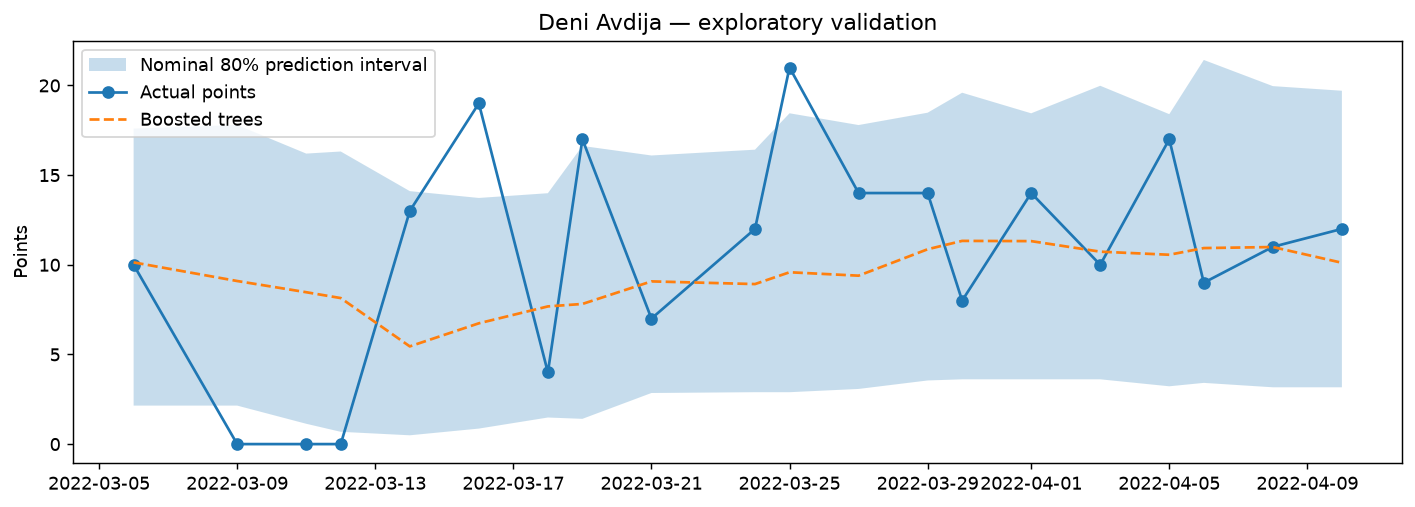

In [ ]:
RUN_UNCERTAINTY = True  # Set False to skip the two extra fits.
quantile_models = {}
interval_report = None

if RUN_UNCERTAINTY:
    quantiles = {}
    for q in [0.1, 0.9]:
        model = HistGradientBoostingRegressor(
            loss="quantile", quantile=q, max_iter=200, max_leaf_nodes=15,
            learning_rate=0.05, l2_regularization=1.0,
            early_stopping=False, random_state=42,
        )
        model.fit(X_train, y_train)
        quantile_models[q] = model
        quantiles[q] = model.predict(X_validation)

    crossing_rate = np.mean(quantiles[0.1] > quantiles[0.9])
    lower = np.maximum(np.minimum(quantiles[0.1], quantiles[0.9]), 0)
    upper = np.maximum(np.maximum(quantiles[0.1], quantiles[0.9]), 0)
    covered = (y_validation >= lower) & (y_validation <= upper)
    interval_score = (upper - lower) + 10 * (
        np.maximum(lower - y_validation, 0) + np.maximum(y_validation - upper, 0)
    )  # 2 / alpha = 10 for alpha = 0.2 (an 80% interval).
    interval_report = {
        "nominal_coverage": 0.8, "observed_coverage": float(covered.mean()),
        "mean_width_points": float(np.mean(upper - lower)),
        "mean_interval_score": float(np.mean(interval_score)),
        "raw_crossing_rate": float(crossing_rate),
        "pinball_10": mean_pinball_loss(y_validation, quantiles[0.1], alpha=0.1),
        "pinball_90": mean_pinball_loss(y_validation, quantiles[0.9], alpha=0.9),
    }
    predictions["lower_80"] = lower
    predictions["upper_80"] = upper
    display(pd.Series(interval_report, name="interval evaluation").to_frame().round(3))

    # Display consecutive appearances for one player, chosen without looking at errors.
    player_id = validation.player_id.value_counts().index[0]
    example = predictions[predictions.player_id == player_id].sort_values("game_date").tail(20)
    plt.figure(figsize=(11, 4))
    plt.fill_between(example.game_date, example.lower_80, example.upper_80,
                     alpha=0.25, label="Nominal 80% prediction interval")
    plt.plot(example.game_date, example[TARGET], "o-", label="Actual points")
    plt.plot(example.game_date, example[SELECTED_MODEL], "--", label=SELECTED_MODEL)
    plt.title(f"{example.player_name.iloc[0]} — {EXPERIMENT} validation")
    plt.ylabel("Points")
    plt.legend()
    plt.tight_layout()
    plt.show()


## 6. Optional: PCA, clustering, and a neural network

Leave this section off for the first run. These are **separate experiments**, not required
steps to stack into one model.

| Technique | Experiment here | How to interpret it |
| --- | --- | --- |
| PCA | Scale → retain 95% of training variance → Ridge | Compresses correlated inputs. With only 18 features it is optional; variance retained does not guarantee predictive information retained. |
| K-means | Scale → distances to 5 training clusters → Ridge | Groups similar **player-game contexts**, not permanent player identities. The distances become regression inputs; clustering alone does not predict points. |
| Neural network | Scale → small multilayer perceptron | Another supervised model. More complexity does not guarantee lower error; inspect convergence warnings and tune using earlier chronological splits. |

All scalers, PCA components, and cluster centers are learned on training data only through
pipelines. The neural network uses L2 regularization (`alpha`) and disables random early-stopping
validation. These scikit-learn models use CPU; selecting a Colab GPU will not accelerate them.
A random forest is another possible tree comparison, but it is not necessary for the first run.


In [ ]:
RUN_EXTRA_MODELS = False

if RUN_EXTRA_MODELS:
    from sklearn.decomposition import PCA
    from sklearn.cluster import KMeans
    from sklearn.neural_network import MLPRegressor

    extra_models = {
        "PCA + Ridge": make_pipeline(StandardScaler(), PCA(n_components=0.95), Ridge(alpha=10)),
        "Cluster distances + Ridge": make_pipeline(
            StandardScaler(), KMeans(n_clusters=5, n_init=10, random_state=42), Ridge(alpha=10)
        ),
        "Neural network": make_pipeline(StandardScaler(), MLPRegressor(
            hidden_layer_sizes=(32, 16), alpha=0.01, max_iter=300,
            early_stopping=False, random_state=42,
        )),
    }
    for name, model in extra_models.items():
        model.fit(X_train, y_train)
        predictions[name] = np.maximum(model.predict(X_validation), 0)
    models.update(extra_models)
    methods = ["Season average", "Ten-game average", *models]
    scores = compare_predictions(methods)
    display(scores.round(3))


## 7. Save the experiment

This saves the explicitly selected model, metrics, per-player predictions, and settings.
Use a new `RUN_NAME` for another feature/model experiment; reruns overwrite that folder.
In Colab these files are temporary until downloaded or copied to Drive. The cell prints
where they were written; you can download them from Colab's Files pane.
Only load pickle files you trust, using compatible package versions.

Keep data downloads/feature construction in the existing Python scripts. Use this notebook
for experiments and presentation. FastAPI can later load the frozen selected model for predictions.


In [ ]:
RUN_NAME = f"notebook_{EXPERIMENT}"
OUTPUT = ROOT / "data/models" / RUN_NAME
OUTPUT.mkdir(parents=True, exist_ok=True)

scores.to_csv(OUTPUT / "metrics.csv")
predictions.to_csv(OUTPUT / "predictions.csv", index=False)
with (OUTPUT / "model.pkl").open("wb") as file:
    pickle.dump({
        "model": models[SELECTED_MODEL], "feature_columns": FEATURES,
        "target_column": TARGET, "prediction_minimum": 0,
        "quantile_models": quantile_models,
        "interval_postprocessing": "sort endpoints, then clamp each to zero",
        "sklearn_version": sklearn.__version__,
    }, file)
report = {
    "experiment": EXPERIMENT, "selected_model": SELECTED_MODEL, "features": FEATURES,
    "training_file": str(DATA_DIR / train_name), "validation_file": str(DATA_DIR / validation_name),
    "training_rows": len(train), "validation_rows": len(validation),
    "training_seasons": sorted(train.season.unique().tolist()),
    "validation_seasons": sorted(validation.season.unique().tolist()),
    "sklearn_version": sklearn.__version__,
    "model_settings": {name: repr(model) for name, model in models.items()},
    "quantile_settings": {str(q): repr(model) for q, model in quantile_models.items()},
    "interval_evaluation": interval_report,
}
(OUTPUT / "report.json").write_text(json.dumps(report, indent=2))
print("Saved results to", OUTPUT)


Saved results to /private/tmp/nba-notebook.sgSArZ/data/models/notebook_exploratory


## What the case study can conclude

This evaluates points **conditional on recorded appearances with sufficient prior history**.
It does not predict whether a player will play, and it excludes early-season/low-history rows.
Compare on identical rows. Keep 2026–27 untouched until feature and model choices are frozen.
A useful result can be that simple averages remain competitive; extra complexity is an empirical question.

References:
- [Colab capabilities and runtime limits](https://research.google.com/colaboratory/faq.html)
- [Ridge and L2 regularization](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
- [Histogram gradient boosting and quantile loss](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html)
- [Prediction interval evaluation](https://scikit-learn.org/stable/auto_examples/ensemble/plot_gradient_boosting_quantile.html)
- [PCA](https://scikit-learn.org/stable/modules/decomposition.html#pca)
- [K-means](https://scikit-learn.org/stable/modules/clustering.html#k-means)
- [Neural networks](https://scikit-learn.org/stable/modules/neural_networks_supervised.html)


## Local verification notes

The saved outputs were generated locally using the exploratory CSVs. All default code cells completed, charts were inspected, and reloaded model predictions matched. The optional PCA, clustering, and neural-network branches were also exercised separately. The neural network reached its 300-iteration limit without converging, so its initial score should not be treated as the best it can achieve. The default notebook keeps these extra branches disabled. The Colab-specific upload dialog has not been tested in a live Colab session.

On this exploratory split the nominal 80% intervals covered about 74.2% of outcomes with a mean width of 14.2 points. This is undercoverage; do not label these as calibrated 80% intervals.
